<a href="https://colab.research.google.com/github/tranchi1701/USSID/blob/main/exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Progress Report #1: Exploration
In this notebook, we will try to do the exploration portion of our project. This progress will consist of 4 steps as shown below:


---


**Step 1: Understand the data**

- Find the size of the dataset (number of rows and columns), identify and categorize the features (categorical, numerical).

**Step 2: Identify relationships between features**

- Find the direction (positive, negative) and strength (strong, moderate, weak) of correlation between the features.

**Step 3: Describe the shape of data**

- Determine the shape of the distribution (symmetric, skewed).

**Step 4: Detect outliers and missing data**

- Find values that are much higher or lower than the rest of the data or values that strongly affect the shape of the data.



In [ ]:
#Importing the data science library
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive #import the drive so we can read the csv in the drive.
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).



## SECTION I: Table 6 analysis

### **Step 1: Import libraries**

- Because the table we import comes from our Drive, we have to use the google.colab.drive.mount method. By using that method, we can import not just table 6, but also all the table from our projects into this colab notebook.

- Also, we would also want to import the other libraries that serves our data work as well, such as pandas, matplotlib and seaborns, just in case we need any of them.

### **Step 2: Import table 6: Selected Measures of Household Income Dispersion: 1967 to 2025**

In [ ]:
#Import table 6
table6 = '/content/drive/Shared drives//USSID/table6(table6) (1).csv'
table6 = pd.read_csv(table6, skiprows = 7, header = None, dtype=str)
table6

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,2025,"20,010","35,800","51,330","68,600","87,460","110,300","140,900","182,400","261,300",...,13.9,22.5,52.4,23.5,0.490,0.613,0.442,0.106,0.208,0.313
1,2024 1,"20,170","35,000","50,240","66,600","85,210","107,600","137,900","179,600","256,900",...,13.9,22.6,52.3,23.2,0.489,0.609,0.439,0.106,0.207,0.312
2,2023,"19,950","34,690","50,360","65,390","84,730","106,100","133,800","173,700","246,900",...,14.1,22.6,51.9,23.0,0.485,0.616,0.429,0.104,0.203,0.309
3,2022,"18,680","32,770","47,990","63,380","81,460","102,700","129,700","167,100","235,900",...,14.0,22.5,52.1,23.5,0.488,0.637,0.440,0.106,0.207,0.315
4,2021,"18,420","32,950","47,670","64,700","83,270","105,600","133,200","175,400","249,400",...,13.9,22.6,52.7,23.5,0.494,0.634,0.448,0.108,0.211,0.320
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,22 Full implementation of 1970 Census-based sa...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
83,23 Introduction of 1970 Census-based sample de...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
84,24 Implementation of a new CPS ASEC processing...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
85,Note: Median income estimates are currently ca...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### **Step 3: Naming the column and Clone dataframe**

- Here, we note that the table 6 has multiple level of column grouping, so what
we are trying to do here is to try to keep the valuable column that is related to the scope of the project. Then, we rename and reformat the table so it can be easier for us to analyze in the future.

- In case there might be something happen to the original table, we cloned the table into a dataframe named df6, and at this point we would work on df6 and leave table6 untouched.
- In the scope of this project, we think we would like to extract the columns as demonstrated from the source table instead of all of them, since some columns may make the analysis become redundant. We extract them by using iloc[], and then make a clone table from those columns.

In [ ]:
df6 = table6.iloc[:, [0,1,5,9,11,26]].copy()

df6.columns = [
    "Years_Original",
    "Income_10th", #income at 10th percentile
    "Median_Income", #income at 50th percentile
    "income_90th", #income at 90th percentile
    "Ratio_10_90", #90th percentile divide by 10th percentile income
    "Gini_index" #measure of income inequality, the higher the gini the more inequality it is
]

df6.tail()

,Years_Original,Income_10th,Median_Income,income_90th,Ratio_10_90,Gini_index
82,22 Full implementation of 1970 Census-based sa...,NaN,NaN,NaN,NaN,NaN
83,23 Introduction of 1970 Census-based sample de...,NaN,NaN,NaN,NaN,NaN
84,24 Implementation of a new CPS ASEC processing...,NaN,NaN,NaN,NaN,NaN
85,Note: Median income estimates are currently ca...,NaN,NaN,NaN,NaN,NaN
86,"Source: U.S. Census Bureau, Current Population...",NaN,NaN,NaN,NaN,NaN


### **Step 4: Clean years, footnotes, and numbers**

- We note that in our table 6, there are some number following the years that is to be used to match the footnote in the legends below our data. Our decision is to keep the footnote for now, then remove the note and the source text below the data.
- Because the year entries are quite complicated since it include both the year and the footnote for us to review in the legend on how the data was collected, we used regex to split the footnote and the year out. Because we have formatted the year and footnote into string to make it easier to format using regex, we might want to take note that we would have to return the year back into integer in the following step.

In [ ]:
df6 = df6 [
    df6["Years_Original"].str.match(r"^\d{4}(?:\s|$)?", na = False)
] #remove source text and notes under the data

df6[["Year", "Footnote"]] = df6["Years_Original"].str.extract(
    r"^(\d{4})(?:\s+(.*))?$"
) #seperate year and footnote

df6 = df6.drop(columns = "Years_Original") #drop the original year column
df6["Footnote"] = df6["Footnote"].fillna("No Footnote")
df6['Footnote'].describe()


,Footnote
count,61
unique,25
top,No Footnote
freq,37


### **Step 5: Make integer entries**

As mentioned before, we have converted the years and footnote into string. But we realised that there are some entries where there are more than 1 footnotes. So we would still keep the footnote column as dtypes('O') (generic type of data rather than just numeric or anything) for future reference if needed

In [ ]:
df6["Year"] = df6["Year"].astype(int)

numeric_col = [
    "Income_10th", #income at 10th percentile
    "Median_Income", #income at 50th percentile
    "income_90th", #income at 90th percentile
    "Ratio_10_90", #90th percentile divide by 10th percentile income
    "Gini_index" #measure of income inequality, the higher the gini the more inequality it is
]

for col in numeric_col:
  df6[col] = pd.to_numeric(
      df6[col].str.replace(',','', regex = False),
      errors = "coerce"
  )

df6 = df6.sort_values("Year").reset_index(drop=True)

df6['Footnote'].dtypes

dtype('O')

## SECTION II: Table 2 analysis


###**Step 1: Import table 2: Households by Total Money Income, Race, and Hispanic Origin of Householder: 1967 to 2025**

- In this step, instead of just doing the usual pd.read_csv() step, we want to skip the first 5 rows containing the headers, and when we land in row 6, we find that there's a special character that threw an error to us. After reading some documentations, we found out the "encoding" parameter that matches exactly to the error message, and we also found out the code to decode that special char too.

In [ ]:
#Import table 2
table2 = '/content/drive/Shared drives/USSID/table2(table2).csv'
table2 = pd.read_csv(table2, skiprows = 5, header = None, dtype=str, encoding="cp1252")
table2

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,ALL RACES,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025,"137,100",100,6.9,6.0,6.3,9.4,14.7,12.0,17.1,10.4,17.2,"87,460","1,040","126,700","1,354"
2,2024 3,"136,200",100,7.1,6.3,6.6,9.8,14.9,11.9,16.7,10.2,16.6,"85,210","1,069","123,600","1,223"
3,2023,"132,200",100,7.1,6.3,6.8,9.6,15.5,12.0,17.1,9.9,15.6,"84,730",667,"120,400","1,154"
4,2022,"131,400",100,7.5,6.8,7.2,9.8,15.3,12.4,17.0,9.7,14.3,"81,460","1,057","116,200","1,129"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
521,24 Full implementation of 1970 Census-based sa...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
522,25 Introduction of 1970 Census-based sample de...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
523,26 Implementation of a new CPS ASEC processing...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
524,Note: Median income estimates are calculated u...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### **Step 2: Give all columns clear names**

First, just like we did with table 6, we cloned table 2 into a df2 table. Then, we also assign names to the columns in the table like we did before.

In [ ]:
df2 = table2.copy()

df2.columns = [
    "Group_or_Year",
    "Households_Thousands",
    "Total_Percent",
    "Under_15000_Percent",
    "15000_to_24999_Percent",
    "25000_to_34999_Percent",
    "35000_to_49999_Percent",
    "50000_to_74999_Percent",
    "75000_to_99999_Percent",
    "100000_to_149999_Percent",
    "150000_to_199999_Percent",
    "200000_and_over_Percent",
    "Median_Income",
    "Median_Margin_of_Error",
    "Mean_Income",
    "Mean_Margin_of_Error"
]

table2.head(20)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,ALL RACES,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025,"137,100",100,6.9,6.0,6.3,9.4,14.7,12.0,17.1,10.4,17.2,"87,460","1,040","126,700","1,354"
2,2024 3,"136,200",100,7.1,6.3,6.6,9.8,14.9,11.9,16.7,10.2,16.6,"85,210","1,069","123,600","1,223"
3,2023,"132,200",100,7.1,6.3,6.8,9.6,15.5,12.0,17.1,9.9,15.6,"84,730",667,"120,400","1,154"
4,2022,"131,400",100,7.5,6.8,7.2,9.8,15.3,12.4,17.0,9.7,14.3,"81,460","1,057","116,200","1,129"
5,2021,"131,200",100,7.6,7.0,6.5,10.2,14.6,11.9,16.6,9.7,15.8,"83,270",712,"120,400","1,211"
6,2020 4,"129,200",100,7.2,7.1,6.6,10.1,14.9,12.0,16.8,9.7,15.6,"83,590","1,082","119,800","1,290"
7,2019,"128,500",100,6.9,6.6,6.6,9.8,15.2,11.9,17.0,10.1,15.9,"85,320","1,123","121,800","1,294"
8,2018,"128,600",100,7.6,7.1,7.1,10.2,15.3,12.6,16.9,9.5,13.7,"79,620",871,"113,400","1,131"
9,2017 5,"127,700",100,7.7,7.3,7.7,10.4,15.1,12.1,16.7,9.3,13.7,"78,600",680,"112,700","1,206"


### **Step 3: Reformat data**
- A data row begins with a four-digit year.
- Group heading rows contain text and no household count.
- Notes at the bottom will be removed when we keep only year rows.
- Put group names into a new column.
- Carry each group name down to its year rows.
- Keep only the year rows.

In [ ]:
is_year = df2["Group_or_Year"].str.match( #step 1
    r"^\d{4}(?:\s|$)",
    na=False
)

is_group = ( #step 2 and 3
    ~is_year #pandas boolean: ~ means is NOT a year row
    & df2["Group_or_Year"].notna() #has text in the first column
    & df2["Households_Thousands"].isna() #has no household count
)

df2["Group"] = df2["Group_or_Year"].where(is_group) # step 4

df2["Group"] = df2["Group"].ffill() #step 5

df2 = df2[is_year].copy() #step 6

df2[["Group", "Group_or_Year"]].head(100)

,Group,Group_or_Year
1,ALL RACES,2025
2,ALL RACES,2024 3
3,ALL RACES,2023
4,ALL RACES,2022
5,ALL RACES,2021
...,...,...
98,WHITE,1993 15
99,WHITE,1992 16
100,WHITE,1991
101,WHITE,1990


In [ ]:
print(df2.columns.tolist()) #this is just for double check

['Group_or_Year', 'Households_Thousands', 'Total_Percent', 'Under_15000_Percent', '15000_to_24999_Percent', '25000_to_34999_Percent', '35000_to_49999_Percent', '50000_to_74999_Percent', '75000_to_99999_Percent', '100000_to_149999_Percent', '150000_to_199999_Percent', '200000_and_over_Percent', 'Median_Income', 'Median_Margin_of_Error', 'Mean_Income', 'Mean_Margin_of_Error', 'Group']


### **Step 4: Clean years, footnotes, and number**
This handles years with one or multiple footnotes, including values like 1974 20, 21.

- Step 1: : Extract the year and any footnote text after it.

- Step 2: : Convert all the measurement columns to numbers.



In [ ]:

df2[["Year", "Footnote"]] = df2["Group_or_Year"].str.extract( #step 1
    r"^(\d{4})(?:\s+(.*))?$"
)

df2["Year"] = df2["Year"].astype(int)
df2["Footnote"] = df2["Footnote"].fillna("No footnote")

numeric_columns = [ #step 2
    "Households_Thousands",
    "Total_Percent",
    "Under_15000_Percent",
    "15000_to_24999_Percent",
    "25000_to_34999_Percent",
    "35000_to_49999_Percent",
    "50000_to_74999_Percent",
    "75000_to_99999_Percent",
    "100000_to_149999_Percent",
    "150000_to_199999_Percent",
    "200000_and_over_Percent",
    "Median_Income",
    "Median_Margin_of_Error",
    "Mean_Income",
    "Mean_Margin_of_Error"
]

for column in numeric_columns:
    df2[column] = pd.to_numeric(
        df2[column].str.replace(",", "", regex=False),
        errors="coerce"
    )

df2 = df2.sort_values(["Group", "Year"]).reset_index(drop=True)

df2.head()

,Group_or_Year,Households_Thousands,Total_Percent,Under_15000_Percent,15000_to_24999_Percent,25000_to_34999_Percent,35000_to_49999_Percent,50000_to_74999_Percent,75000_to_99999_Percent,100000_to_149999_Percent,150000_to_199999_Percent,200000_and_over_Percent,Median_Income,Median_Margin_of_Error,Mean_Income,Mean_Margin_of_Error,Group,Year,Footnote
0,1967 26,60810.0,100,12.0,9.4,8.4,14.5,23.6,15.6,11.5,3.0,1.9,56230,337.0,62890.0,337.0,ALL RACES,1967,26
1,1968,62210.0,100,10.9,9.0,8.5,13.8,22.9,17.0,12.8,3.2,1.8,58630,349.0,66330.0,349.0,ALL RACES,1968,No footnote
2,1969,63400.0,100,10.8,8.4,8.2,12.6,23.0,16.5,14.4,3.7,2.2,60940,370.0,69330.0,358.0,ALL RACES,1969,No footnote
3,1970,64780.0,100,11.0,8.7,8.4,12.9,22.2,16.3,14.5,3.9,2.3,60490,365.0,69270.0,365.0,ALL RACES,1970,No footnote
4,1971 25,66680.0,100,10.7,9.1,8.9,12.9,21.8,16.1,14.2,4.1,2.3,59970,382.0,68980.0,361.0,ALL RACES,1971,25


## SECTION III: "State of California - Income Inequality" TABLE ANALYSIS

### Step 1: Importing data
Since this Excel file consists of columns that contains repeated informations, we can just extract those that are useful for our research for future reference.

In [ ]:
#Import the California dataset
tableraw = pd.read_excel(
    '/content/drive/Shared drives/USSID/gini_place_county_region_st3-26-14-ada (1).xlsx',
    sheet_name="gini_place_county",
    dtype=str
)

tableraw.head()

/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,ind_id,ind_definition,reportyear,race_eth_code,race_eth_name,geotype,geotypevalue,geoname,county_name,county_fips,...,Gini_index,LL_95CI,UL_95CI,se,rse,CA_decile,CA_RR,Median_HH_income,Median_HH_decile,version
0,556,Income inequality: Gini coefficient describing...,2005-2007,9,Total,CA,06,California,NaN,NaN,...,0.468,0.465617021276596,0.470382978723404,0.00121580547112462,0.259787493830047,NaN,NaN,NaN,NaN,2014-03-26 09:50:34
1,556,Income inequality: Gini coefficient describing...,2006-2010,9,Total,CA,06,California,NaN,NaN,...,0.469,0.467808510638298,0.470191489361702,0.00060790273556231,0.129616787966377,NaN,NaN,NaN,NaN,2014-03-26 09:50:34
2,556,Income inequality: Gini coefficient describing...,2008-2010,9,Total,CA,06,California,NaN,NaN,...,0.471,0.468617021276596,0.473382978723404,0.00121580547112462,0.258132796417117,NaN,NaN,NaN,NaN,2014-03-26 09:50:34
3,556,Income inequality: Gini coefficient describing...,2005-2007,9,Total,CO,06001,Alameda,Alameda,06001,...,0.455,0.449042553191489,0.460957446808511,0.00303951367781155,0.668024984134407,NaN,0.972222222222222,66430,3,2014-03-26 09:50:34
4,556,Income inequality: Gini coefficient describing...,2005-2007,9,Total,CO,06003,Alpine,Alpine,06003,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014-03-26 09:50:34


### Step 2: Data inclusion
This step is to clone out the useful information that we need, as said earlier. This would include these columns:
- "reportyear",
- "geotype",
- "geotypevalue",
- "geoname",
- "county_name",
- "region_name",
- "Households",
- "Gini_index",
- "Median_HH_income",
- "LL_95CI",
- "UL_95CI"

In [ ]:
caldf = tableraw.iloc[:, [2, 5, 6, 7, 8, 10, 13, 14, 21, 15, 16]].copy()
caldf

,reportyear,geotype,geotypevalue,geoname,county_name,region_name,Households,Gini_index,Median_HH_income,LL_95CI,UL_95CI
0,2005-2007,CA,06,California,NaN,NaN,12577498,0.468,NaN,0.465617021276596,0.470382978723404
1,2006-2010,CA,06,California,NaN,NaN,12577498,0.469,NaN,0.467808510638298,0.470191489361702
2,2008-2010,CA,06,California,NaN,NaN,12577498,0.471,NaN,0.468617021276596,0.473382978723404
3,2005-2007,CO,06001,Alameda,Alameda,Bay Area,545138,0.455,66430,0.449042553191489,0.460957446808511
4,2005-2007,CO,06003,Alpine,Alpine,Central/Southeast Sierra,497,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
4784,2008-2010,RE,11,San Luis Obispo,NaN,San Luis Obispo,102016,0.447,NaN,0.433893617021277,0.460106382978723
4785,2008-2010,RE,12,Santa Barbara,NaN,Santa Barbara,142104,0.476,NaN,0.462893617021277,0.489106382978723
4786,2008-2010,RE,13,Shasta,NaN,Shasta,70346,0.452,NaN,0.436510638297872,0.467489361702128
4787,2008-2010,RE,14,Southern California,NaN,Southern California,5847909,0.469890683148455,NaN,0.468092846004338,0.471688520292572


## SECTION IV: DATA EXPLORATION REPORT

| Step | Description |
|---|---|
|Step 1: Understand the data|Find the size of the dataset (number of rows and columns), identify and categorize the features (categorical, numerical).|
|Step 2: Identify relationships between features|Find the direction (positive, negative) and strength (strong, moderate, weak) of correlation between the features.|
|Step 3: Describe the shape of data|Determine the shape of the distribution (symmetric, skewed).|
|Step 4: Detect outliers and missing data|Find values that are much higher or lower than the rest of the data or values that strongly affect the shape of the data.|

- **STEP 1:** Identify **numerical** and **categorical** features in your dataset and list them out with their ranges and category values.

- **STEP 2:** Show an example of each of the following single feature plots on your dataset. Explain the results of each plot briefly.
    * sns.histplot(df, x='Feature')
    * sns.kdeplot(df, x='Feature')
    * sns.countplot(df, x='Feature')
    * sns.boxplot(df, x='Feature')
    * sns.violinplot(df, x='Feature')

- **STEP 3:** Show an example of each of the following two feature plots on the  dataset. Use hue, style, and size parameters as well. Explain the results of each plot briefly.
    * sns.scatterplot(df, x='Horizontal feature', y='Vertical feature')
    * sns.swarmplot(df, x='Numerical feature', y='Categorical feature')
    * sns.stripplot(df, x='Numerical feature', y='Categorical feature')

- **STEP 4:** Summarize the dataset using the following methods:
  * df.shape
  * df.info()
  * df.describe(include = "all")

- **STEP 5:** Show examples of the following visualization methods on selected dataset columns. Try to interpret the results that are interesting and useful. Useful methods:
  * df.hist()
  * df.boxplot()
  * pd.plotting.scatter_matrix(df)

- **STEP 6:** Try to find outliers in the dataset such as the following, show examples, and show how you are cleaning them. (see below)
|Cause of outlier|Description of cause|Method of cleaning|
|---|---|---|
|Data entry error|Human error entering a value into the dataset|If the intended value can be inferred, correct the value.|
|Measurement error|Error in an instrument recording the value|If the error is consistently biased from the actual value and can be identified, remove the bias.|
|Data processing error|Accident in data manipulation|If feasible, redo the manipulation to remove the error.|
|Sampling error|Error in combining data from multiple populations or groups|Explore dataset for outliers that may be from different populations or groups.|
|Natural outlier|Not an error. This value, though extreme, belongs in the data.|Models should be checked for stability of results with and without the outlier.|



### **TABLE 6 EXPLORATION**


#### Step 1. Identify numerical and categorical features in your dataset and list them out with their ranges and category values:


In [ ]:
df6.dtypes

,0
Income_10th,int64
Median_Income,int64
income_90th,int64
Ratio_10_90,float64
Gini_index,float64
Year,int64
Footnote,object


As can be seen, all attributes in table 6 are all **NUMERICAL** values

#### Step 2. Show an example of each of the following single feature plots on your dataset. Explain the results of each plot briefly.

<Axes: xlabel='Median_Income'>

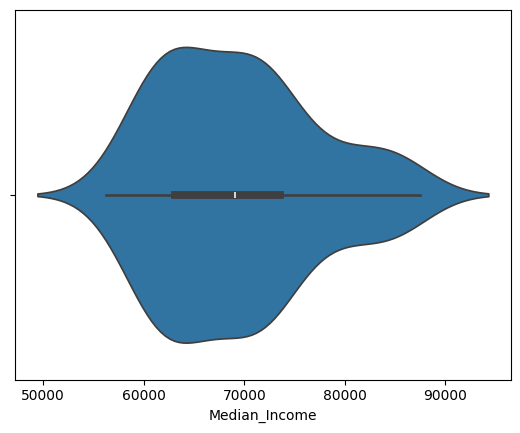

In [ ]:
sns.violinplot(df6, x='Median_Income') #This is a violin plot of the "median income" column in table 6.

<Axes: xlabel='Income_10th', ylabel='Density'>

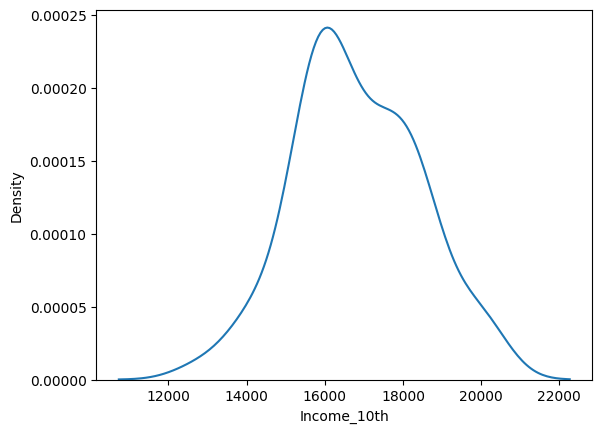

In [ ]:
sns.kdeplot(df6, x='Income_10th') #This is a density plot of the "Income (10th percentile)" numerical feature from the table 6.

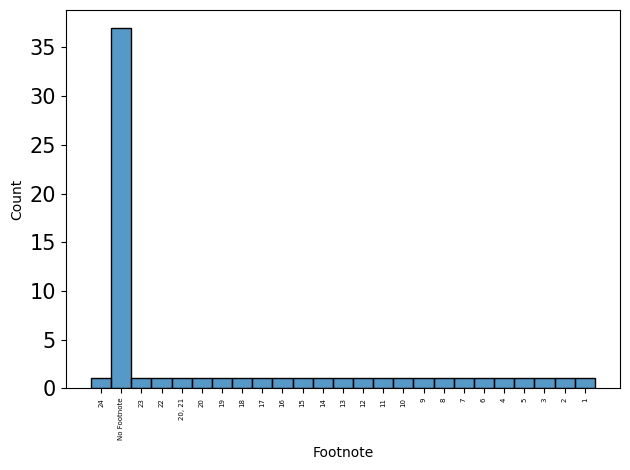

In [ ]:
ax = sns.histplot(data=df6, x='Footnote')
ax.tick_params(axis='x', labelsize=5, labelrotation=90)
ax.tick_params(axis='y', labelsize=15)
plt.tight_layout()

<Axes: xlabel='Ratio_10_90'>

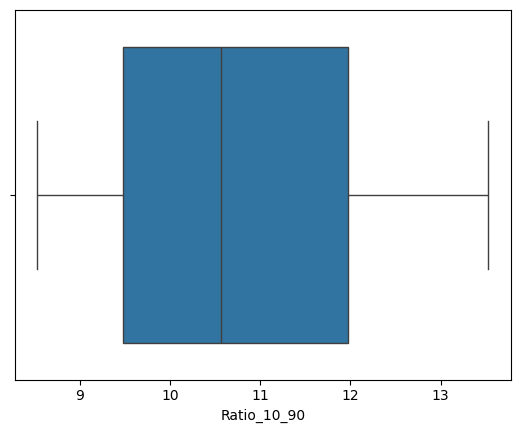

In [ ]:
sns.boxplot(df6, x='Ratio_10_90') #this boxplot represent the mean,median and spread of the "Ratio of 10th and 90th percentile" column from table 6

<Axes: xlabel='Gini_index', ylabel='Count'>

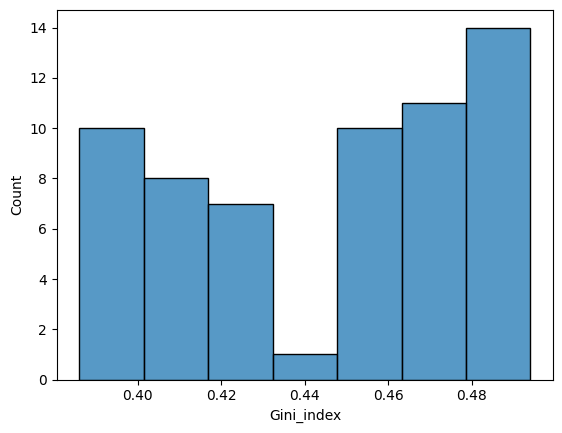

In [ ]:
sns.histplot(df6, x='Gini_index') #this histogram shows the distribution of each range of the gini index column

#### Step 3. Show an example of each of the following two feature plots on the  dataset. Use hue, style, and size parameters  as well.  Explain the results of each plot briefly.

<Axes: xlabel='Median_Income', ylabel='Gini_index'>

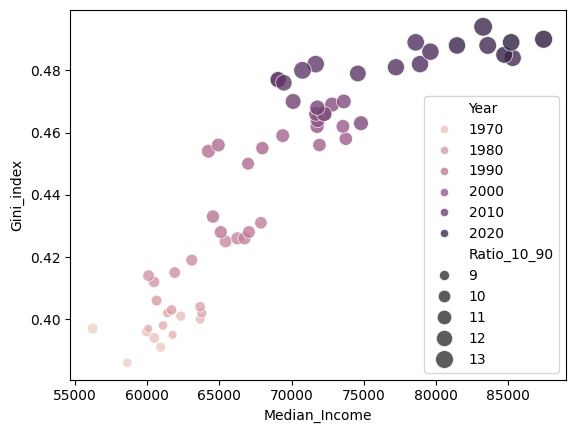

In [ ]:
sns.scatterplot( #here, we picked median income for horizontal feature, gini index for vertical feature, year for hue and ratio 10th percentile over 90th for size
    data=df6,
    x="Median_Income",
    y="Gini_index",
    hue="Year",
    size="Ratio_10_90",
    sizes=(40, 180),
    alpha=0.8
)

<Axes: xlabel='Year', ylabel='Footnote'>

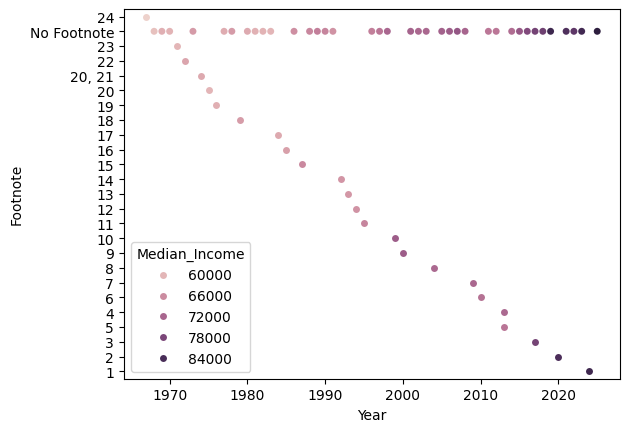

In [ ]:
sns.swarmplot(df6, x='Year', y='Footnote', hue = 'Median_Income')

<Axes: xlabel='Income_10th', ylabel='Decade'>

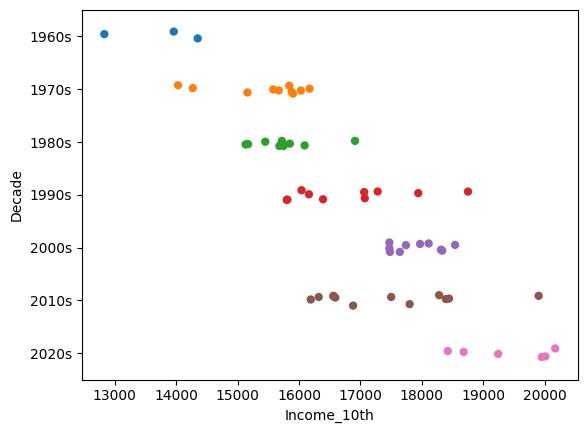

In [ ]:
df6["Decade"] = (df6["Year"] // 10 * 10).astype(str) + "s"

sns.stripplot(
    data=df6,
    x="Income_10th",
    y="Decade",
    hue="Decade",
    size=6,
    jitter=True
)

#### Step 4. Summarize the dataset

In [ ]:
df6.shape

(61, 8)

This dataframe has 61 rows, 8 columns

In [ ]:
df6.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Income_10th    61 non-null     int64  
 1   Median_Income  61 non-null     int64  
 2   income_90th    61 non-null     int64  
 3   Ratio_10_90    61 non-null     float64
 4   Gini_index     61 non-null     float64
 5   Year           61 non-null     int64  
 6   Footnote       61 non-null     object 
 7   Decade         61 non-null     object 
dtypes: float64(2), int64(4), object(2)
memory usage: 3.9+ KB


According to the code, there are 8 features, all contain non-null records, and they are recorded as numerical values

In [ ]:
df6.describe(include = "all")

,Income_10th,Median_Income,income_90th,Ratio_10_90,Gini_index,Year,Footnote,Decade
count,61.000000,61.000000,61.000000,61.000000,61.000000,61.000000,61,61
unique,NaN,NaN,NaN,NaN,NaN,NaN,25,7
top,NaN,NaN,NaN,NaN,NaN,NaN,No Footnote,2010s
freq,NaN,NaN,NaN,NaN,NaN,NaN,37,12
mean,16826.065574,69357.868852,181698.360656,10.699508,0.445410,1996.622951,NaN,NaN
std,1589.039835,7755.708030,38655.609734,1.425230,0.034393,17.231912,NaN,NaN
min,12830.000000,56230.000000,118400.000000,8.530000,0.386000,1967.000000,NaN,NaN
25%,15800.000000,63090.000000,145200.000000,9.480000,0.412000,1982.000000,NaN,NaN
50%,16560.000000,69070.000000,183100.000000,10.570000,0.456000,1997.000000,NaN,NaN
75%,17970.000000,73560.000000,202500.000000,11.970000,0.477000,2012.000000,NaN,NaN


This table sums up the statistics (count, mean, standard deviation, min/max, and quartiles) for each numerical feature. Including include = "all" displays the count, number of categories, and mode's name and frequency for categorical features.

#### Step 5. Visualization on selected columns and Interpretation

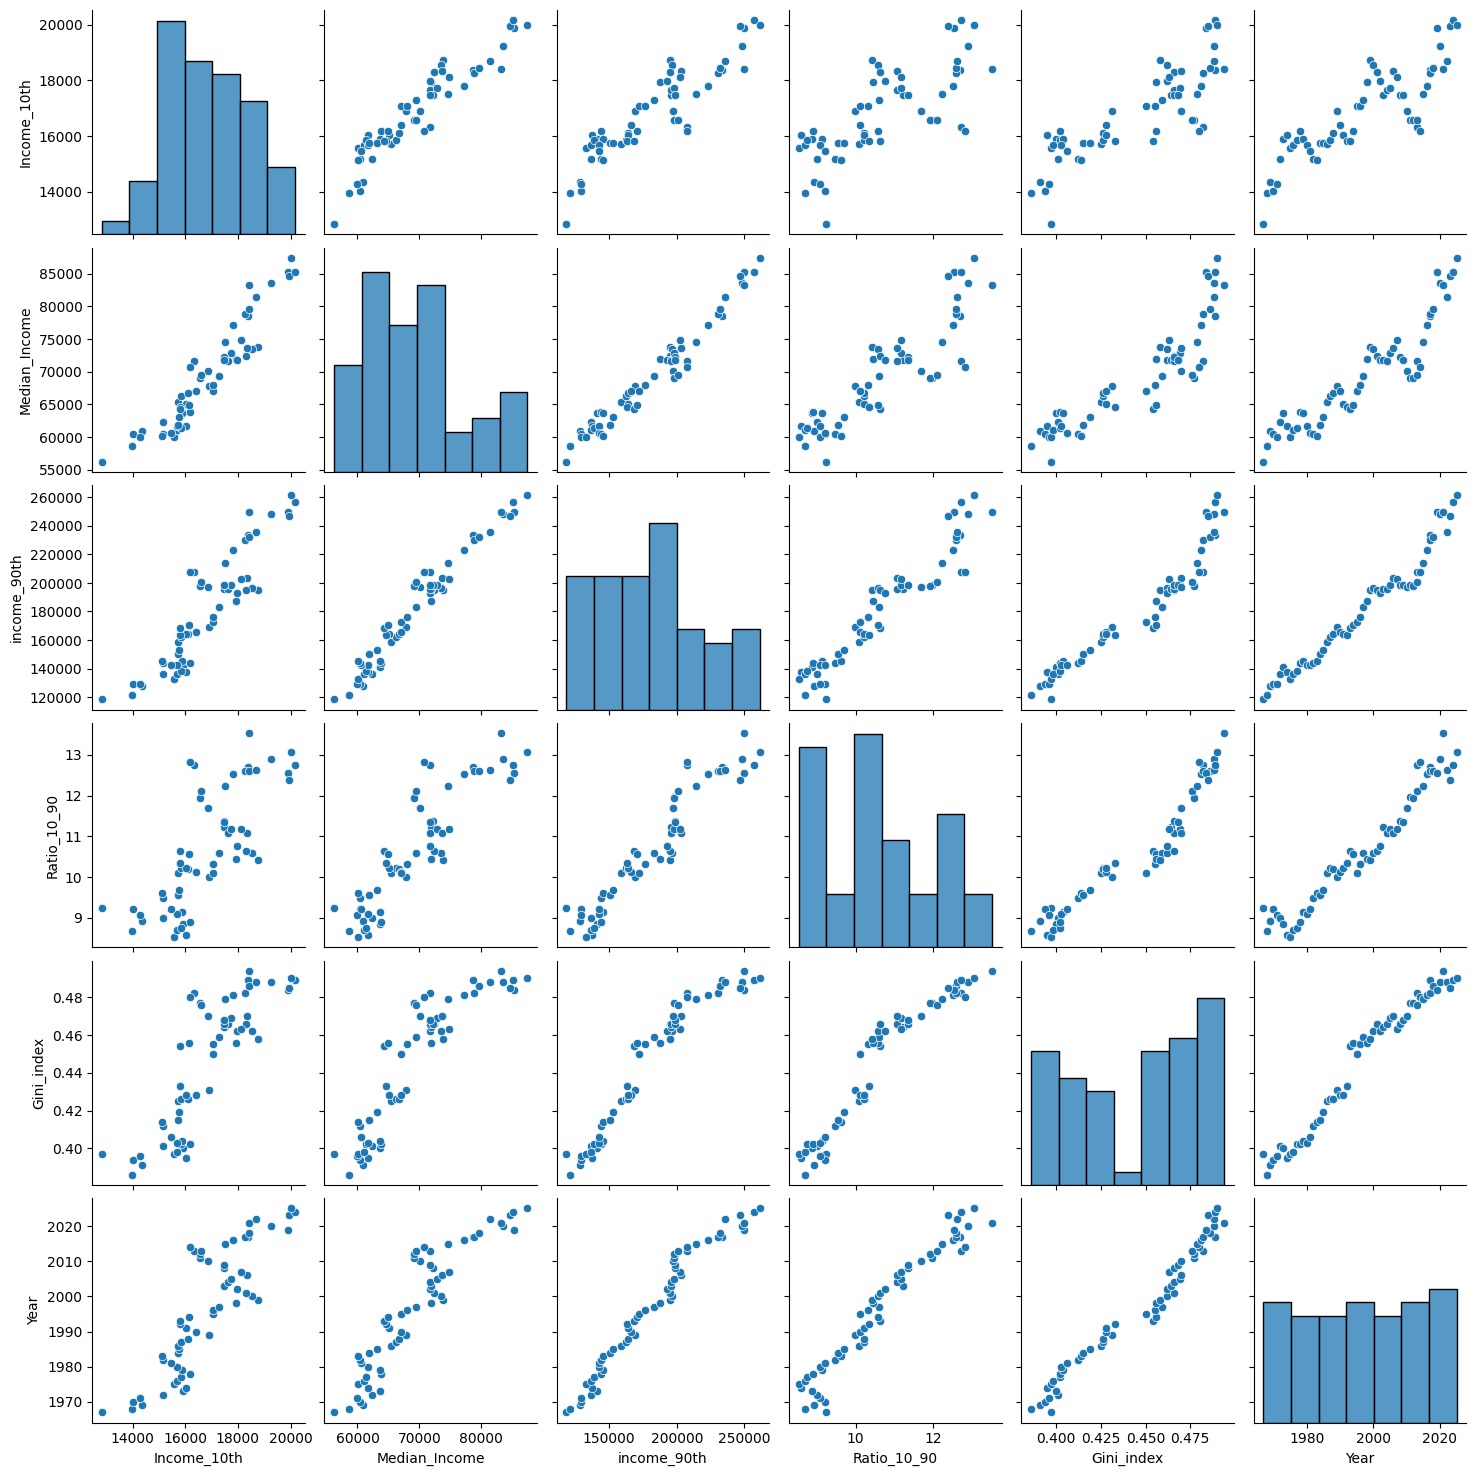

In [ ]:
sns.pairplot(df6)

In this matrix plot, we printed out all the possible combination of the scatterplot of each pair of feature to have a general view on the data shape, outliers and check on whether a pair would be useful for our future analysis. Here, we found out that doing a time-series analytic would be very suitable for our vision. But before coming to that, we may want to analyze some features pairwise with time as the horizontal feature:

- Income_10th and Year: See how the 10th percentile of earning change over the years.
- Median_Income and Year: See how the median income change over years
- Income_90th and Year: See how the 90th percentile of earning change over the years.
- Ratio_10_90 and Year: See how the ratio between the 90th and the 10th percentile of earning change over the years.
- Gini_index and Year: although all are important, looking at the Gini index, which is being coined as a standard for measuring inequality, over the year still remain our main scope of table 6 in the project, since it aligns perfectly to our hypothesis introduced in our initial proposal report.

Also, by looking at this general picture, we notice that while the median and the 10th percentile had a plummet around the 2010 (we suspect it is because of the [2008 great depression](https://en.wikipedia.org/wiki/Great_Recession)), the 90th percentile income and the ratio between the 10th and 90th percentile still consistently climbed up. Should this be questioned further into our research later?

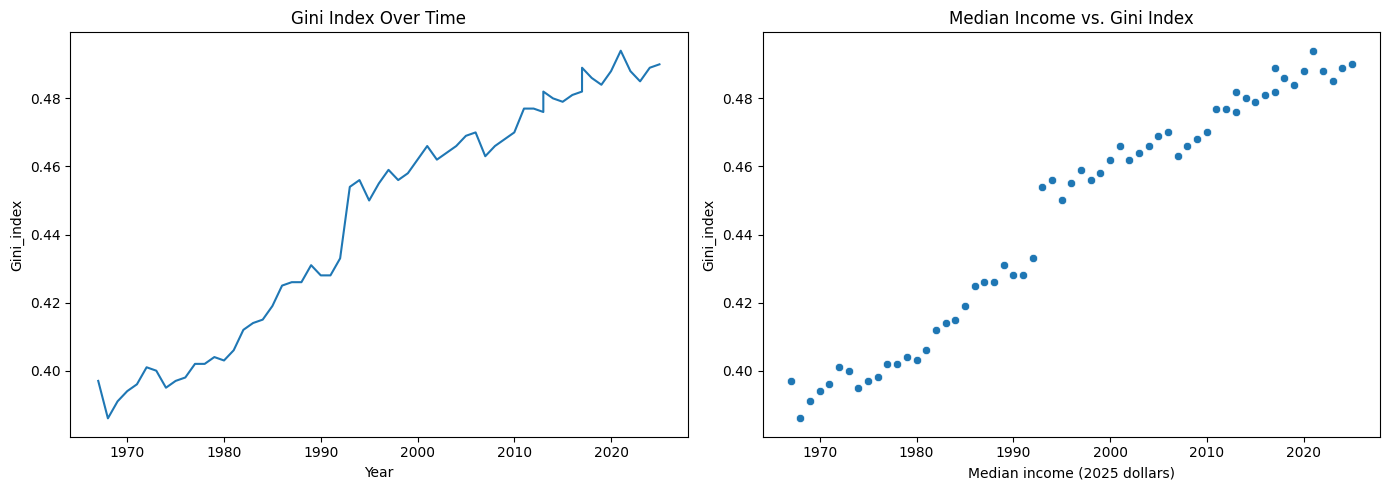

In [ ]:
plot_data = df6.sort_values("Year")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Line chart
sns.lineplot(
    data=plot_data,
    x="Year",
    y="Gini_index",
    estimator=None,
    ax=axes[0]
)
axes[0].set_title("Gini Index Over Time")

# Plot 2: Scatterplot
sns.scatterplot(
    data=plot_data,
    x="Year",
    y="Gini_index",
)
axes[1].set_title("Median Income vs. Gini Index")
axes[1].set_xlabel("Median income (2025 dollars)")

plt.tight_layout()
plt.show()

Using a subplot, we found out, for some reason the Gini index around 1990s just rocketted from around just roughly 0.43 to 0.45 - that's 2 degrees for us. We suspect this links to another financial crisis: [the early 1990 recession](https://en.wikipedia.org/wiki/Early_1990s_recession_in_the_United_States).

#### Step 6. Outliers identification, analysis and resolution

To identify outliers, we would like to make a sub-dataframe (a separate working copy) for checking outliers

In [ ]:
features = [
    "Income_10th",
    "Median_Income",
    "income_90th",
    "Ratio_10_90",
    "Gini_index"
]

outlier_data = df6.copy()

display(outlier_data[["Year"] + features].head())

,Year,Income_10th,Median_Income,income_90th,Ratio_10_90,Gini_index
0,1967,12830,56230,118400,9.23,0.397
1,1968,13960,58630,121200,8.68,0.386
2,1969,14350,60940,128100,8.93,0.391
3,1970,14030,60490,129300,9.22,0.394
4,1971,14270,59970,129500,9.08,0.396


We implement the IQR check for checking outliers. This follows the convention where outliers below Q1-1.5IQR or above Q3+1.5IQR

In [ ]:
values = outlier_data[features]

q1 = values.quantile(0.25)
q3 = values.quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outlier_flags = values.lt(lower) | values.gt(upper)

summary = pd.DataFrame({
    "Minimum": values.min(),
    "Lower_bound": lower,
    "Upper_bound": upper,
    "Maximum": values.max(),
    "Outlier_count": outlier_flags.sum(),
    "Missing_count": values.isna().sum()
})

display(summary.round(3))

,Minimum,Lower_bound,Upper_bound,Maximum,Outlier_count,Missing_count
Income_10th,12830.000,12545.000,21225.000,20170.000,0,0
Median_Income,56230.000,47385.000,89265.000,87460.000,0,0
income_90th,118400.000,59250.000,288450.000,261300.000,0,0
Ratio_10_90,8.530,5.745,15.705,13.530,0,0
Gini_index,0.386,0.314,0.574,0.494,0,0


As can be seen, there are no outliers according to the IQR test. But we also want to have a look at what is called "extreme values".

In [ ]:
display( # this display the 3 lowest 10th-percentile incomes
    outlier_data.nsmallest(3, "Income_10th")[
        ["Year", "Income_10th", "Median_Income", "Gini_index"]
    ]
)

display( # display the 3 highest 90th-percentile incomes
    outlier_data.nlargest(3, "income_90th")[
        ["Year", "income_90th", "Median_Income", "Gini_index"]
    ]
)

,Year,Income_10th,Median_Income,Gini_index
0,1967,12830,56230,0.397
1,1968,13960,58630,0.386
3,1970,14030,60490,0.394


,Year,income_90th,Median_Income,Gini_index
60,2025,261300,87460,0.490
59,2024,256900,85210,0.489
54,2019,249800,85320,0.484


Then moving on, we want to check and display the data that falls into processing errors, as definition from before.

In [ ]:
invalid_order = (
    (outlier_data["Income_10th"] > outlier_data["Median_Income"])
    | (outlier_data["Median_Income"] > outlier_data["income_90th"])
)

invalid_gini = (
    outlier_data["Gini_index"].notna()
    & ~outlier_data["Gini_index"].between(0, 1)
)

calculated_ratio = (# we think we should allow a small difference because published values are rounded.
    outlier_data["income_90th"] / outlier_data["Income_10th"]
)

ratio_mismatch = (
    calculated_ratio - outlier_data["Ratio_10_90"]
).abs() > 0.05

checks = pd.DataFrame({
    "Invalid_percentile_order": invalid_order,
    "Invalid_Gini": invalid_gini,
    "Ratio_mismatch": ratio_mismatch
})

print("Number of records failing each check:")
display(checks.sum())

display(
    outlier_data.loc[
        checks.any(axis=1),
        ["Year"] + features
    ]
)

Number of records failing each check:


,0
Invalid_percentile_order,0
Invalid_Gini,0
Ratio_mismatch,0


,Year,Income_10th,Median_Income,income_90th,Ratio_10_90,Gini_index


In conclusion, this table 6 does not fall into any outliers or error checks. We may say these data are clean and natural.

### **TABLE 2 EXPLORATION**

#### Step 1. Identify numerical and categorical features in your dataset and list them out with their ranges and category values:


In [ ]:
df2.dtypes

,0
Group_or_Year,object
Households_Thousands,float64
Total_Percent,int64
Under_15000_Percent,float64
15000_to_24999_Percent,float64
25000_to_34999_Percent,float64
35000_to_49999_Percent,float64
50000_to_74999_Percent,float64
75000_to_99999_Percent,float64
100000_to_149999_Percent,float64


#### Step 2. Show an example of each of the following single feature plots on your dataset. Explain the results of each plot briefly.

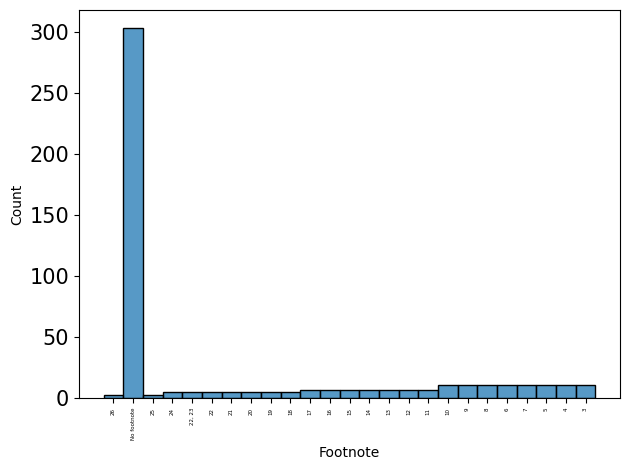

In [ ]:
ax = sns.histplot(data=df2, x='Footnote')
ax.tick_params(axis='x', labelsize=4, labelrotation=90)
ax.tick_params(axis='y', labelsize=15)
plt.tight_layout()

<Axes: xlabel='Mean_Income', ylabel='Density'>

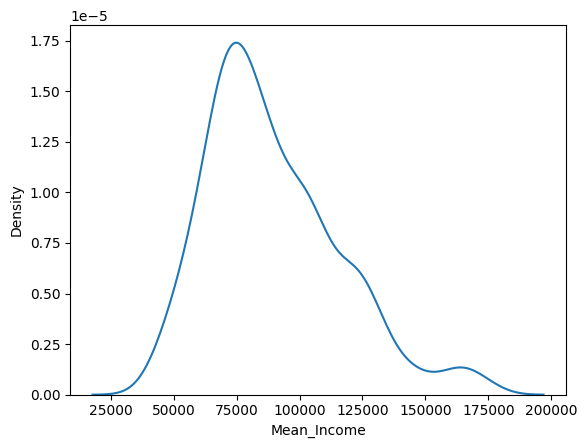

In [ ]:
sns.kdeplot(df2, x='Mean_Income')

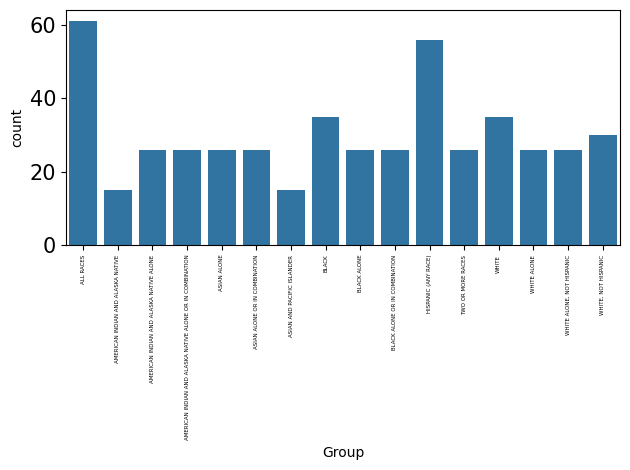

In [ ]:
ax = sns.countplot(data=df2, x='Group')
ax.tick_params(axis='x', labelsize=4, labelrotation=90)
ax.tick_params(axis='y', labelsize=15)
plt.tight_layout()

<Axes: xlabel='Median_Income'>

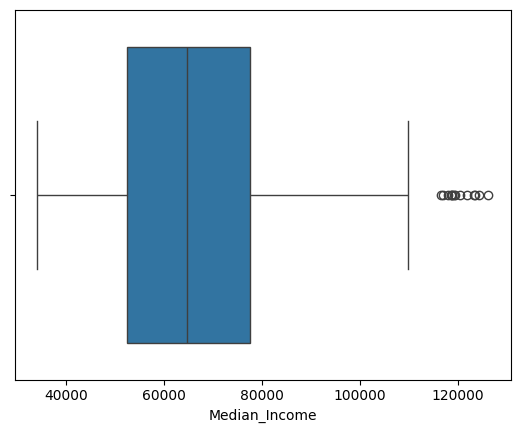

In [ ]:
sns.boxplot(df2, x='Median_Income')

<Axes: xlabel='Year'>

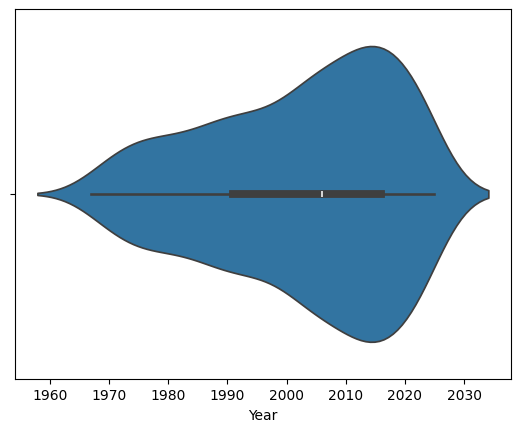

In [ ]:
sns.violinplot(df2, x='Year')

#### Step 3. Show an example of each of the following two feature plots on the  dataset. Use hue, style, and size parameters  as well.  Explain the results of each plot briefly.

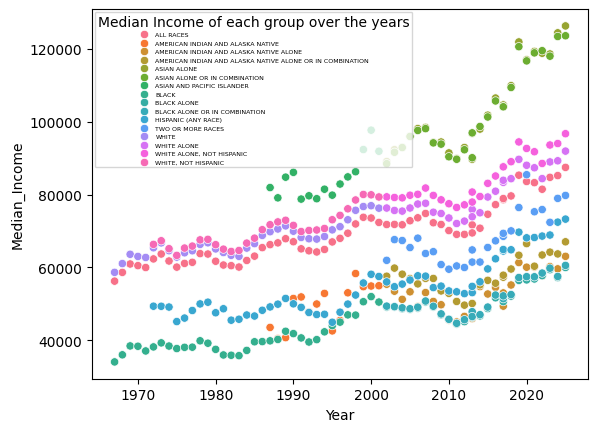

In [ ]:
sns.scatterplot(df2, x='Year', y='Median_Income', hue = "Group") #table 2 step 5 (sample code and interpretation)
plt.legend(title='Median Income of each group over the years', fontsize=4.5, title_fontsize=10)
plt.show() #This scatterplot shows the relationships between the median income of each group (in different hue/color) over the years. As we can see, although all of them has an upward trend, some still rise faster than the others

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 33.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 20.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 28.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 14.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 36.4% of the points cannot be plac

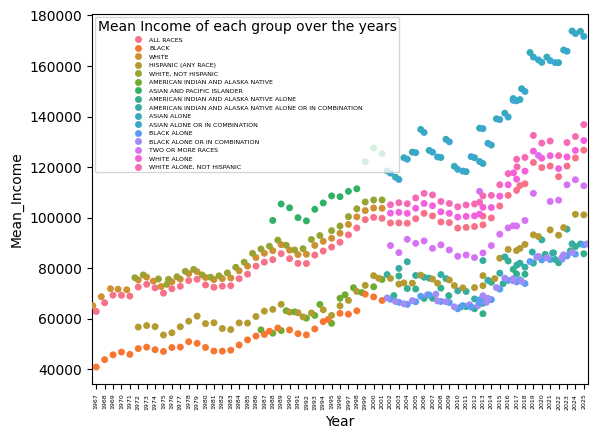

In [ ]:
sns.swarmplot(df2, x='Year', y='Mean_Income', hue="Group")
plt.legend(title='Mean Income of each group over the years', fontsize=4.5, title_fontsize=10)
plt.xticks(fontsize=4.5, rotation=90)
plt.show()

<Axes: xlabel='Mean_Income', ylabel='Group'>

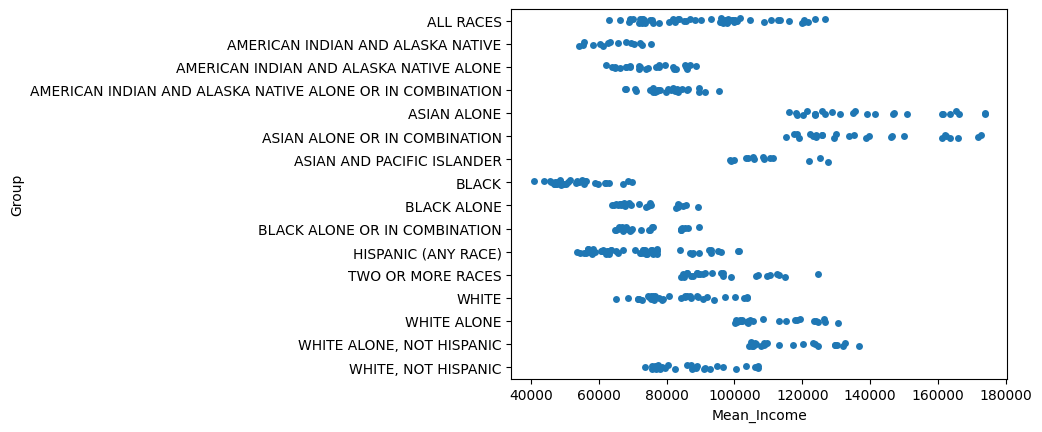

In [ ]:
sns.stripplot(df2, x='Mean_Income', y='Group')

#### Step 4. Summarize the dataset

In [ ]:
df2.shape

(481, 19)

In [ ]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 481 entries, 0 to 480
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Group_or_Year             481 non-null    object 
 1   Households_Thousands      480 non-null    float64
 2   Total_Percent             481 non-null    int64  
 3   Under_15000_Percent       481 non-null    float64
 4   15000_to_24999_Percent    481 non-null    float64
 5   25000_to_34999_Percent    481 non-null    float64
 6   35000_to_49999_Percent    481 non-null    float64
 7   50000_to_74999_Percent    481 non-null    float64
 8   75000_to_99999_Percent    481 non-null    float64
 9   100000_to_149999_Percent  481 non-null    float64
 10  150000_to_199999_Percent  481 non-null    float64
 11  200000_and_over_Percent   481 non-null    float64
 12  Median_Income             481 non-null    int64  
 13  Median_Margin_of_Error    460 non-null    float64
 14  Mean_Incom

In [ ]:
df2.describe(include = "all")

,Group_or_Year,Households_Thousands,Total_Percent,Under_15000_Percent,15000_to_24999_Percent,25000_to_34999_Percent,35000_to_49999_Percent,50000_to_74999_Percent,75000_to_99999_Percent,100000_to_149999_Percent,150000_to_199999_Percent,200000_and_over_Percent,Median_Income,Median_Margin_of_Error,Mean_Income,Mean_Margin_of_Error,Group,Year,Footnote
count,481,480.000000,481.0,481.000000,481.000000,481.000000,481.000000,481.000000,481.000000,481.000000,481.000000,481.000000,481.000000,460.000000,480.000000,457.000000,481,481.000000,481
unique,61,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16,NaN,25
top,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ALL RACES,NaN,No footnote
freq,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,61,NaN,303
mean,NaN,37412.220833,100.0,10.469231,9.185031,8.700208,11.933264,16.850520,12.586486,14.947401,7.060915,8.266528,66810.124740,1901.900000,89457.104167,2511.947484,NaN,2002.544699,NaN
std,NaN,40875.974773,0.0,4.098288,2.729191,1.994028,2.351856,2.417283,1.802176,3.122158,2.878666,6.285511,18601.112388,1630.293195,26431.877875,2378.979530,NaN,15.635649,NaN
min,NaN,469.000000,100.0,5.300000,3.600000,3.700000,6.000000,10.600000,8.300000,4.400000,1.100000,0.300000,34050.000000,324.000000,40910.000000,337.000000,NaN,1967.000000,NaN
25%,NaN,4113.500000,100.0,7.300000,7.500000,7.600000,10.700000,15.600000,11.400000,12.500000,5.000000,3.700000,52410.000000,631.500000,70690.000000,801.000000,NaN,1991.000000,NaN
50%,NaN,14375.000000,100.0,9.000000,8.900000,8.500000,12.200000,16.700000,12.400000,16.000000,6.800000,6.700000,64560.000000,1242.000000,84420.000000,1524.000000,NaN,2006.000000,NaN
75%,NaN,78085.000000,100.0,13.200000,10.900000,10.100000,13.400000,18.200000,13.500000,17.500000,9.300000,10.900000,77480.000000,3036.250000,105025.000000,3969.000000,NaN,2016.000000,NaN


#### Step 5. Visualization on selected columns and Interpretation

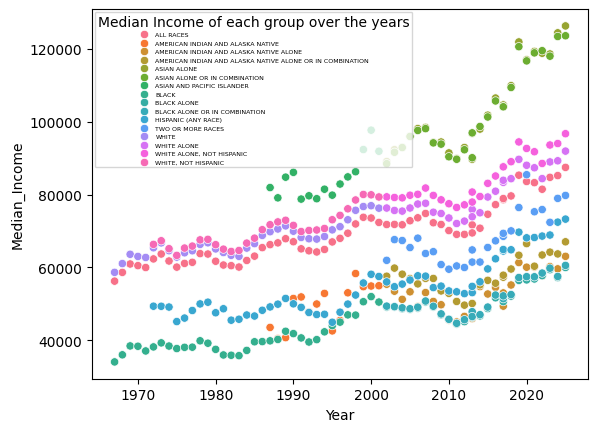

In [ ]:
sns.scatterplot(df2, x='Year', y='Median_Income', hue = "Group") #table 2 step 5 (sample code and interpretation)
plt.legend(title='Median Income of each group over the years', fontsize=4.5, title_fontsize=10)
plt.show() #This scatterplot shows the relationships between the median income of each group (in different hue/color) over the years. As we can see, although all of them has an upward trend, some still rise faster than the others

This scatterplot above shows the median income for each race over the past couple of decades. Based on the scatterplot, the asians have the highest median income, followed by the white, American Indians, hispanics, and black groups. The median income for each group has started to increase over time.

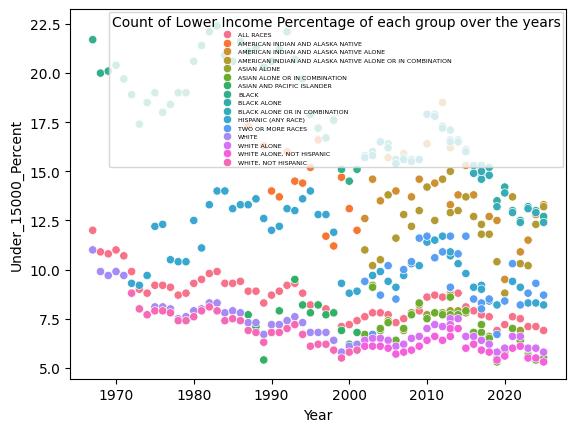

In [ ]:
sns.scatterplot(df2, x='Year', y='Under_15000_Percent', hue = "Group") #table 2 step 5 (sample code and interpretation)
plt.legend(title='Count of Lower Income Percentage of each group over the years', fontsize=4.5, title_fontsize=10)
plt.show() #This scatterplot shows the relationships between the percentage of the people who in the "under $15000 percentage" group. While some group experience dramatical fluctuations, some changes relatively consistent (e.g "White alone, not Hispanic"). This implies there may be many outliers to be resolved



The scatterplot above shows the percentage of people from each group that makes under 15000 dollars from the past couple of decades. The group that is at the top is made of black people. That means that they have make the least amount of money with about 22.5% of people making less than 15000 dollars. The graph is almost inverted since now the white and asian groups have the lowest percentage with about 12.5% or less. As the table progresses, it shows that every group percentage is going down. This means that less people are making less than 15000 dollars. There is a bit of a dramatic change towards the top. The black group goes not a bit, then it goes up and finally drops considerably.



/tmp/ipykernel_254/2610935299.py:2: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Count of Group Appearance over the years', fontsize=4.5, title_fontsize=10)


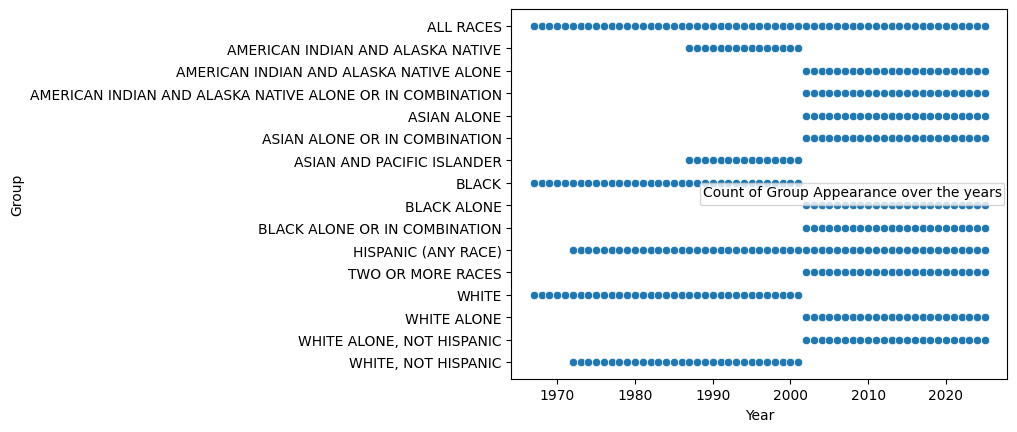

In [ ]:
sns.scatterplot(df2, x='Year', y='Group') #table 2 step 5 (sample code and interpretation)
plt.legend(title='Count of Group Appearance over the years', fontsize=4.5, title_fontsize=10)
plt.show() #As can be seen, the values counts varies accross the group. Some disruptingly stopped or start at 2000. This implies that around 2000, there may be a new method or procedures of statistics gathering came into the play, so we must have a look at the documentation of table 2 to have a better look about how we should use the data to avoid bias and misinformation

This table shows every instance this group appeared on the dataset from each year. One notable thing is there is no data for the asian group from the 1970-2000. There is data for Asians and Pacific Islanders, but that is due to the data from the Pacific Islanders only. Alaskan Natives also don't have much data. It seems that around the year 2000, they started to take into account the other races. It might be due to the fact that the number of Asians and Alaskan Natives were far less back then.

#### Step 6. Outliers identification, analysis and resolution

There are a couple of outliers, specificaly in the "Count of Lower Income Percentage of each group over the years" table. There is one outlier that has a green dot(asian) towards the bottom(close to the year 1990). This makes it the one of if not potentially the lowest percantage in this table. While this isn't the only outlier, it is the most noticable one. It could be an error on the input. It could be an error, but it could also be an extreme value. This value is not to far off the other values that are in the asian group.

### **CALIFORNIA INEQUALITY DATA EXPLORATION**

#### Step 1. Identify numerical and categorical features in your dataset and list them out with their ranges and category values:


In [ ]:
caldf.dtypes

,0
reportyear,object
geotype,object
geotypevalue,object
geoname,object
county_name,object
region_name,object
Households,object
Gini_index,object
Median_HH_income,object
LL_95CI,object


#### Step 2. Show an example of each of the following single feature plots on your dataset. Explain the results of each plot briefly.

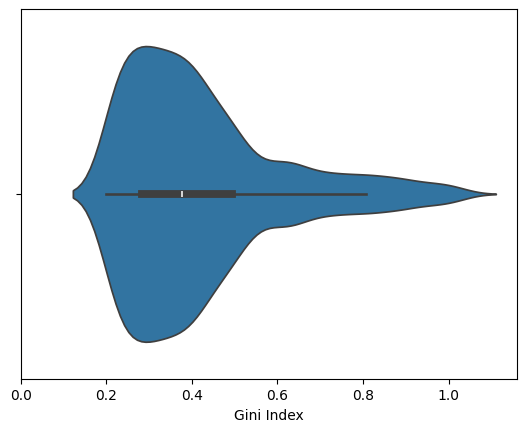

In [ ]:
sns.violinplot(caldf, x='Gini_index')
plt.xlabel("Gini Index")
plt.xticks([-100, 0, 100, 200, 300, 400],[0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
plt.show()

#### Step 3. Show an example of each of the following two feature plots on the  dataset. Use hue, style, and size parameters  as well.  Explain the results of each plot briefly.

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 10.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 41.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


<Axes: xlabel='reportyear', ylabel='Gini_index'>

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 25.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 52.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 20.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


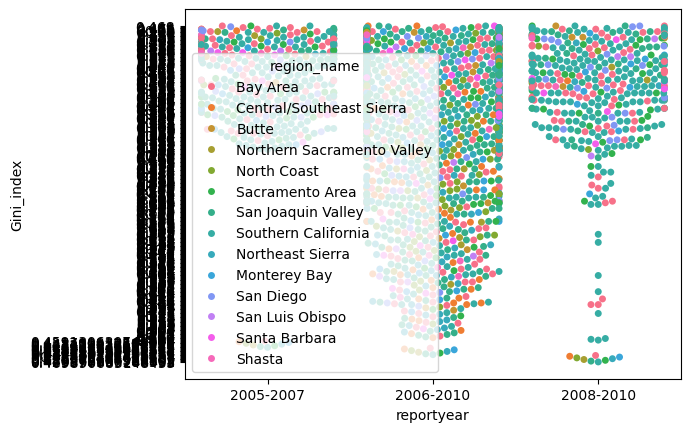

In [ ]:
sns.swarmplot(caldf, x='reportyear', y='Gini_index', hue = "region_name")

#### Step 4. Summarize the dataset

In [ ]:
caldf.shape

(4789, 11)

In [ ]:
caldf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4789 entries, 0 to 4788
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   reportyear        4788 non-null   object
 1   geotype           4788 non-null   object
 2   geotypevalue      4788 non-null   object
 3   geoname           4788 non-null   object
 4   county_name       4743 non-null   object
 5   region_name       4785 non-null   object
 6   Households        4788 non-null   object
 7   Gini_index        2345 non-null   object
 8   Median_HH_income  1967 non-null   object
 9   LL_95CI           2345 non-null   object
 10  UL_95CI           2345 non-null   object
dtypes: object(11)
memory usage: 411.7+ KB


In [ ]:
caldf.describe(include = "all")

,reportyear,geotype,geotypevalue,geoname,county_name,region_name,Households,Gini_index,Median_HH_income,LL_95CI,UL_95CI
count,4788,4788,4788,4788,4743,4785,4788,2345,1967,2345,2345
unique,3,4,1595,1581,58,14,1286,417,1918,2058,2038
top,2005-2007,PL,06,Franklin CDP,Los Angeles,Southern California,85,0.407,51250,0,0.424255319148936
freq,1596,4569,6,6,426,1077,24,29,3,21,4


#### Step 5. Visualization on selected columns and Interpretation

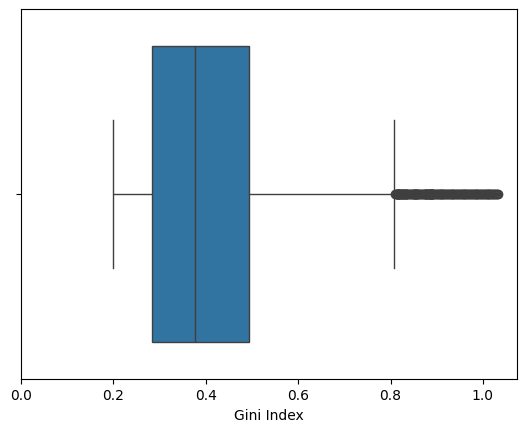

In [ ]:
sns.boxplot(caldf, x = 'Gini_index')
plt.xlabel("Gini Index")
plt.xticks([-100, 0, 100, 200, 300, 400],[0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
plt.show()

The boxplot shows that most of the most of the counties in California have a Gini Index value between 0.3 and 0.5.

#### Step 6. Outliers identification, analysis and resolution

The dataset has a lot of empty values for the Gini Index. This could potentially skew the data a bit. In the box plot that is shown, it shows that most of the Gini Index values for these counties are between .3 and .5. Missing data might change could potentially change the average.

Also, as discovered in the third scatterplot, some groups have missing data can be traced back to the fact that either the general group got broken up and split into different subgroups after 2000s, or it maybe because their data was insufficient back then. We will try to have a better look into this problem to resolve it so we could have a good insight from it.